# Getting started with COAST: human and mouse kidney

COAST orders cross-sections of a repeated tissue structure along one continuous axis, the **pseudostructure**
coordinate, and then asks which genes change along it. This tutorial runs the whole method on the kidney data of
the paper: Visium HD sections of two healthy mouse kidneys and two sections of one healthy human kidney cortex.
Every unit is one segmented tubule cross-section.

**Input.** One AnnData of raw counts per section, one row per unit, genes named by the symbols of that species.
Making these matrices from the image and the bins is the segmentation step; COAST starts after it. The matrices
are not part of this repository; they will be released with the paper. Some outputs are left out below.

In [1]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

import coast

sc.settings.verbosity = 0
DATA = Path("data")
SAMPLES = {"Ctrl1A2": "Mouse", "Ctrl1A4": "Mouse", "HUK1_COR1": "Human", "HUK1_MED1": "Human"}

units = {}
for sample in SAMPLES:
    units[sample] = ad.read_h5ad(DATA / f"{sample}.h5ad")
    units[sample].obs_names = sample + "_" + units[sample].obs_names
{sample: a.shape for sample, a in units.items()}

{'Ctrl1A2': (13630, 19059),
 'Ctrl1A4': (14592, 19059),
 'HUK1_COR1': (8747, 18132),
 'HUK1_MED1': (14186, 18132)}

## 1. One gene space for both species

Compare species only on genes with a one-to-one ortholog. Here the table comes from
[HCOP](https://www.genenames.org/tools/hcop/), one row per human-mouse pair. Keep pairs where:

- each symbol occurs once in the table (one-to-many and many-to-many pairs are dropped), and
- both genes are measured in their species. The human and mouse probe panels differ, and a gene missing from one
  panel would read as zero expression, which it is not.

Human genes are then renamed to their mouse symbols, and the sections are stacked.

In [2]:
mouse_genes, human_genes = units["Ctrl1A2"].var_names, units["HUK1_COR1"].var_names
orthologs = pd.read_csv(DATA / "orthologs.csv")[["human_symbol", "mouse_symbol"]]
orthologs = orthologs[~orthologs["human_symbol"].duplicated(keep=False) & ~orthologs["mouse_symbol"].duplicated(keep=False)]
orthologs = orthologs[orthologs["human_symbol"].isin(human_genes) & orthologs["mouse_symbol"].isin(mouse_genes)]

for sample, species in SAMPLES.items():
    if species == "Human":
        units[sample] = units[sample][:, orthologs["human_symbol"].to_numpy()].copy()
        units[sample].var_names = orthologs["mouse_symbol"].to_numpy()
    else:
        units[sample] = units[sample][:, orthologs["mouse_symbol"].to_numpy()].copy()

adata = ad.concat(units, label="sample")
adata.obs["species"] = adata.obs["sample"].map(SAMPLES).astype("category")
print(f"{len(orthologs)} shared 1:1 orthologs, {adata.n_obs} units")

15567 shared 1:1 orthologs, 51155 units


## 2. Filter and normalise

`filter_units` drops units with fewer than 500 counts, then units whose depth or number of detected genes is more
than 3 robust SDs from their section's median. `normalize` keeps raw counts in `layers['counts']`, which the gene
models use, and log-normalises `X`.

In [3]:
adata = coast.pp.filter_units(adata, groupby="sample")
coast.pp.normalize(adata)
adata.obs["sample"].value_counts()

sample
Ctrl1A2      8895
Ctrl1A4      8167
HUK1_MED1    6962
HUK1_COR1    6280
Name: count, dtype: int64

## 3. Integrate and label clusters

`integrate` selects variable genes, runs PCA and removes section effects with Harmony (`obsm['X_harmony']`).
`group_key="species"` keeps only genes variable in both species, so the correction never sees the genes that
differ between species, which are the genes compared later.

Each Leiden cluster takes the name of its best-scoring marker panel. `label_clusters` returns the cluster x panel
score table; inspect it before trusting a label.

In [4]:
coast.pp.integrate(adata, batch_key="sample", group_key="species")
sc.tl.leiden(adata, resolution=2, flavor="igraph", n_iterations=2, random_state=0)

panels = {
    "Podocyte": ["Nphs1", "Nphs2", "Podxl"],
    "PT-S1": ["Slc5a2", "Slc5a12", "Gatm"],
    "PT-S2": ["Slc22a6", "Slc13a3", "Cyp2e1"],
    "PT-S3": ["Slc7a13", "Slc22a7", "Cyp7b1"],
    "DTL1": ["Corin", "Uncx", "Slc14a2"],
    "DTL2": ["Fst", "Cdh13", "Stk32a"],
    "DTL3": ["Nr2e3", "Dmkn"],
    "ATL": ["Clcnka", "Sptssb", "Akr1b3"],
    "mTAL": ["Slc12a1", "Umod", "Cldn10", "Ptger3"],
    "cTAL": ["Slc12a1", "Umod", "Cldn16", "Kcnj10"],
    "Macula-densa": ["Nos1", "Ptgs2", "Pappa2"],
    "DCT1": ["Slc12a3", "Pvalb", "Trpm6", "Egf"],
    "DCT2": ["Slc12a3", "Trpv5", "Slc8a1", "S100g"],
    "CNT": ["Calb1", "Slc8a1", "Aqp2", "Rhcg"],
    "CCD": ["Aqp2", "Aqp3", "Kit"],
    "OMCD": ["Aqp2", "Atp6v0d2", "Rhcg"],
    "IMCD": ["Aqp2", "Aqp4", "Slc14a2", "Wnt7b"],
    "Vessel": ["Pecam1", "Cdh5", "Kdr", "Emcn", "Flt1", "Egfl7"],
    "Stroma": ["Col1a1", "Col3a1", "Col1a2", "Dcn", "Pdgfrb", "Mgp"],
    "SmoothMuscle": ["Acta2", "Myh11", "Tagln", "Rgs5", "Pdgfra"],
    "Immune": ["Ptprc", "C1qa", "C1qb", "Cd52", "Lyz2", "Cd74"],
}
scores = coast.tl.label_clusters(adata, panels)

In [ ]:
scores.round(2)

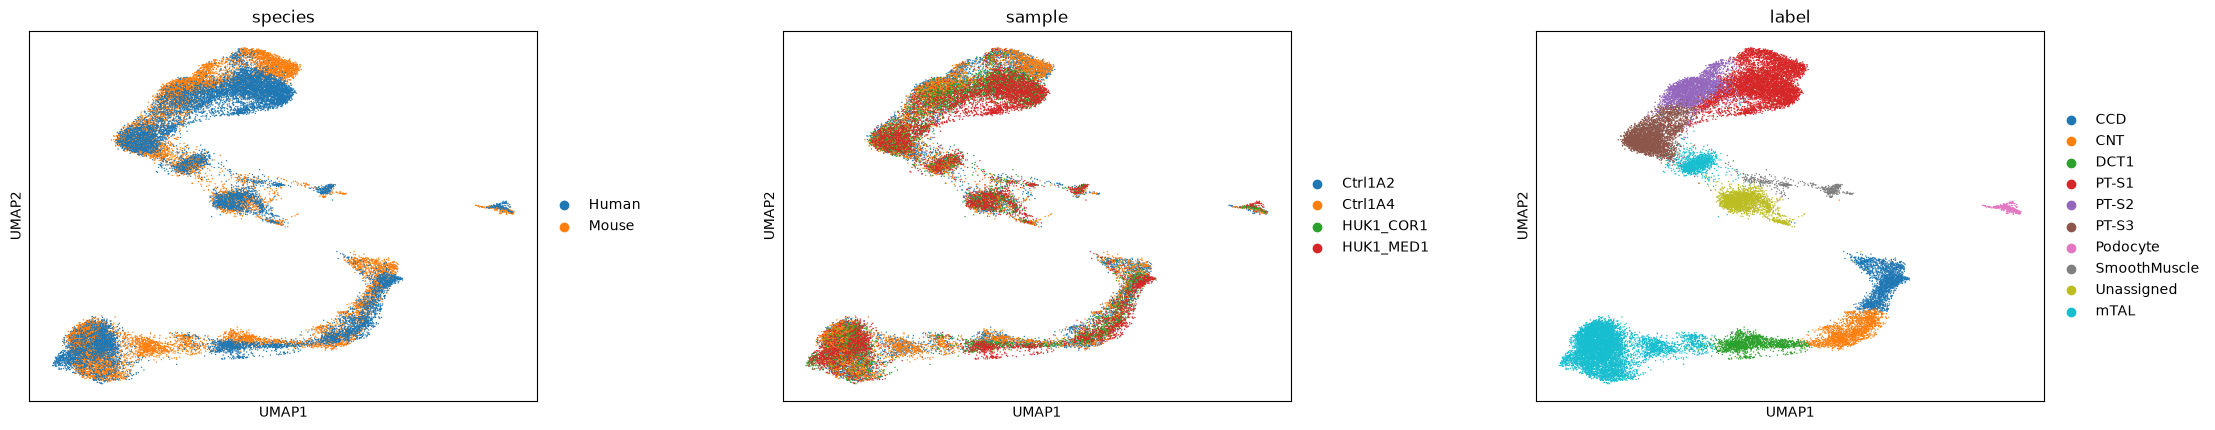

In [5]:
sc.pl.umap(adata, color=["species", "sample", "label"], wspace=0.35)

Keep the nephron tubule segments and integrate again. The second pass builds the embedding from the tubules
alone, which gives a cleaner axis. `X` is already normalised per unit, so it is not recomputed.

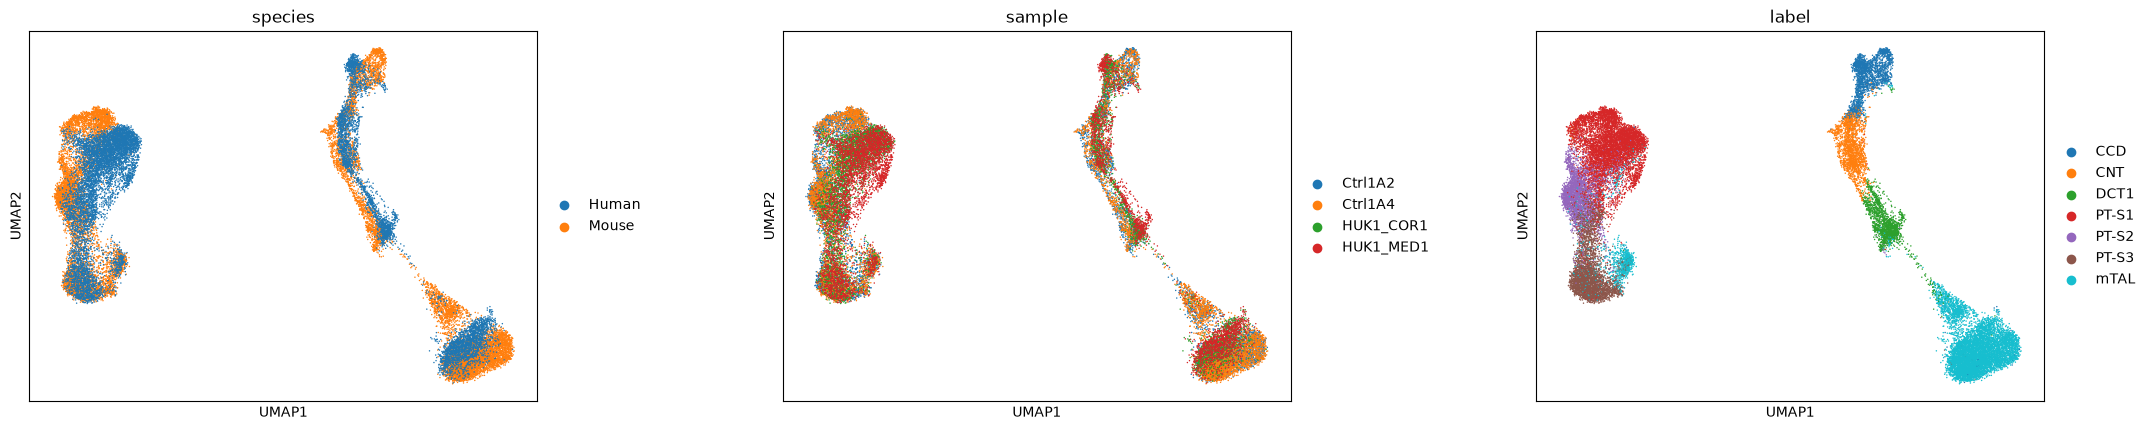

In [6]:
nephron = ["PT-S1", "PT-S2", "PT-S3", "DTL1", "DTL2", "DTL3", "mTAL", "cTAL", "Macula-densa",
           "DCT1", "DCT2", "CNT", "CCD", "OMCD", "IMCD"]
adata = adata[adata.obs["label"].isin(nephron)].copy()
adata.obs["label"] = adata.obs["label"].cat.remove_unused_categories()
coast.pp.integrate(adata, batch_key="sample", group_key="species")
sc.pl.umap(adata, color=["species", "sample", "label"], wspace=0.35)

## 4. The pseudostructure coordinate

`pseudostructure` fits an elastic principal curve (ElPiGraph; 50 nodes) through the 50 Harmony dimensions and
projects every unit onto it. Units beyond either end are placed on the continuation of the end edge instead of
being piled onto the end node. Marker genes only set the direction: 0 at the early markers (proximal tubule), 1 at
the late ones (collecting duct). Cluster labels never enter the fit.

In [7]:
early = ["Cyp2e1", "Gatm", "Slc13a3", "Slc22a6", "Slc5a12", "Slc5a2"]
late = ["Aqp2", "Aqp4", "Atp6v0d2", "Rhcg", "Slc14a2", "Wnt7b"]
coast.tl.pseudostructure(adata, early_genes=early, late_genes=late)

Maximum number of iterations ( 10 ) has been reached. diff =  0.04287617520143905


`pl.curve` draws the units and the curve. With `basis="X_umap"` the units are drawn on the UMAP, and each
curve node at the median UMAP position of the units nearest to it in the Harmony space. This only places the curve
for display; the fit is the same.

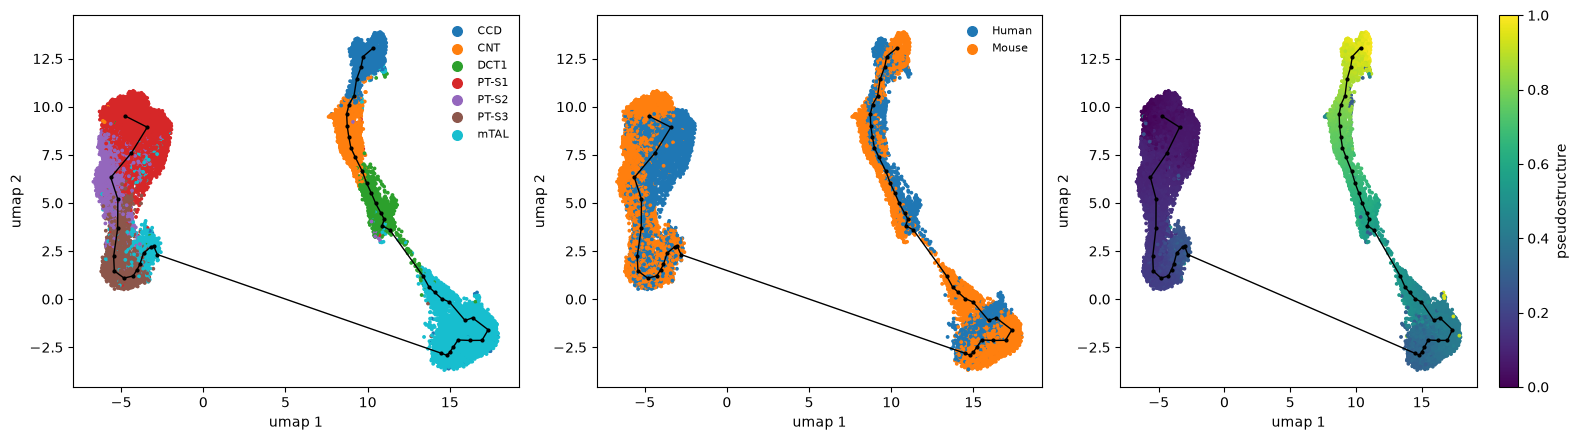

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, color in zip(axes, ["label", "species", "pseudostructure"]):
    coast.pl.curve(adata, color=color, basis="X_umap", ax=ax)
plt.tight_layout()

Segment markers should peak in nephron order along the coordinate, in both species. `fit_curves` gives each
gene's fitted expression along the coordinate (log2 counts per 10k), and `pl.heatmap` z-scores every gene and
orders genes by where they peak. The whole nephron has sharp segment boundaries, so the spline here gets more
degrees of freedom (`df=12`) than the default.

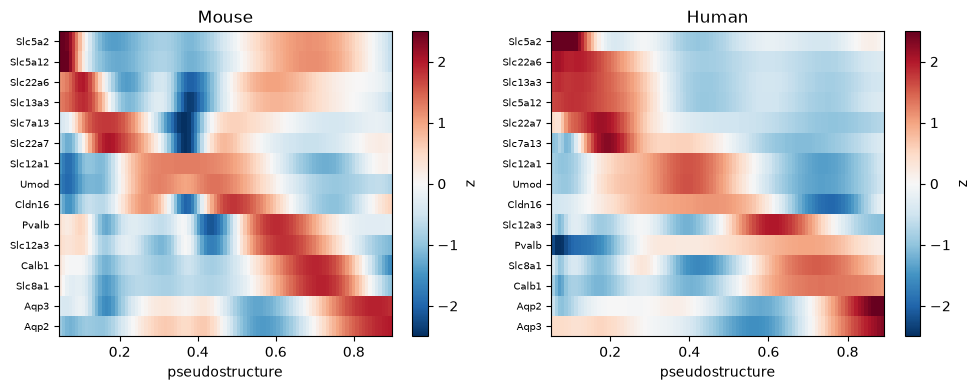

In [9]:
markers = ["Slc5a2", "Slc5a12", "Slc22a6", "Slc13a3", "Slc7a13", "Slc22a7", "Slc12a1", "Umod", "Cldn16",
           "Slc12a3", "Pvalb", "Calb1", "Slc8a1", "Aqp2", "Aqp3"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, species in zip(axes, ["Mouse", "Human"]):
    curves = coast.tl.fit_curves(adata[adata.obs["species"] == species], markers, df=12)
    coast.pl.heatmap(curves, ax=ax)
    ax.set_title(species)
plt.tight_layout()

## 5. Genes along the proximal tubule

Genes are tested within one segment at a time; here the proximal tubule. Start with the segment markers: S1 (Slc5a12), S2 (Slc13a3) and S3 (Slc16a9). `pl.genes` shows binned data
(points) and a negative-binomial spline fit (line), one colour per species, over the 5th to 95th percentile of the
coordinate.

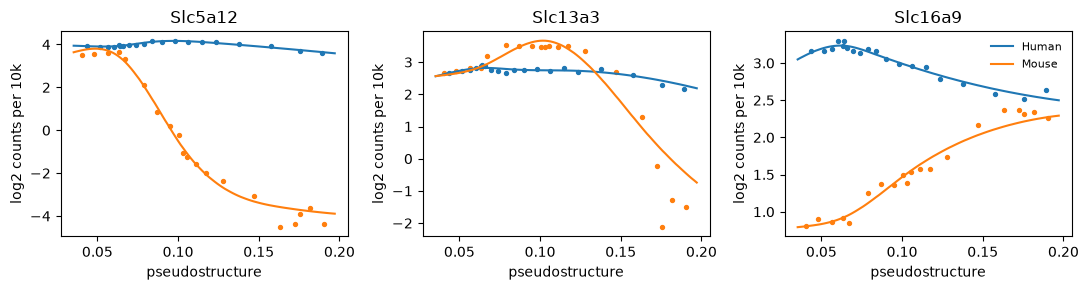

In [10]:
pt = adata[adata.obs["label"].isin(["PT-S1", "PT-S2", "PT-S3"])].copy()
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
coast.pl.genes(pt, ["Slc5a12", "Slc13a3", "Slc16a9"], sample_key="species", axes=axes)
plt.tight_layout()

`sample_key` can be any obs column. One line per section shows whether a pattern replicates within each
species.

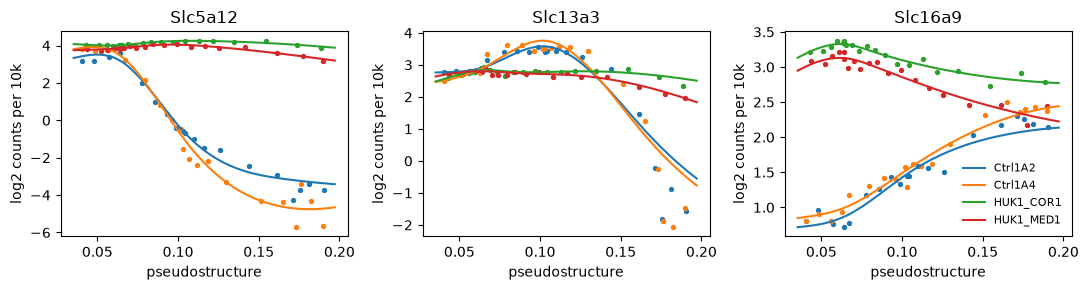

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
coast.pl.genes(pt, ["Slc5a12", "Slc13a3", "Slc16a9"], sample_key="sample", axes=axes)
plt.tight_layout()

`test_genes` fits a negative-binomial GLM per gene to raw counts, with a log(library) offset and a cubic spline in the coordinate, and compares it with an
intercept-only model. Units of one structure are not independent, so genes are called against a **decoy**: the same
fits with the coordinate shuffled. `significant` keeps genes above the first threshold where decoy calls / real
calls <= 5%. With thousands of units tiny shifts are significant, so also require an effect size: `log2_range` is
the size of the fitted pattern in log2 units.

Test every section on its own and keep genes that replicate. To keep this run short only the integration genes are
tested; pass `genes=None` to test all.

In [12]:
genes = pt.var_names[pt.var["coast_feature"]]

def replicated(results):
    return pd.concat({s: r["significant"] & (r["log2_range"] >= 1) for s, r in results.items()}, axis=1).all(axis=1)

positional = {s: coast.tl.test_genes(pt[pt.obs["sample"] == s], genes=genes, n_jobs=-1) for s in SAMPLES}
mouse = replicated({s: positional[s] for s in ["Ctrl1A2", "Ctrl1A4"]})
human = replicated({s: positional[s] for s in ["HUK1_COR1", "HUK1_MED1"]})

In [ ]:
pd.crosstab(mouse.rename("mouse"), human.rename("human"))

**Beyond clusters.** With `groupby`, the null model has one mean per cluster (here S1/S2/S3), so a gene is
called only when the curve explains it better than steps between segments.

In [13]:
beyond = {s: coast.tl.test_genes(pt[pt.obs["sample"] == s], groupby="label", genes=genes, n_jobs=-1) for s in SAMPLES}
mouse_beyond = replicated({s: beyond[s] for s in ["Ctrl1A2", "Ctrl1A4"]})

In [ ]:
mouse_beyond.sum()

`fit_curves` returns each gene's fitted expression along the coordinate (log2 counts per 10k); `pl.heatmap`
z-scores every gene and orders genes by where they peak.

In [ ]:
mouse_pt = pt[pt.obs["species"] == "Mouse"]
curves = coast.tl.fit_curves(mouse_pt, mouse.index[mouse])
coast.pl.heatmap(curves);